In [1]:
%load_ext autoreload
%autoreload 2

In [68]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision

from src.data import PoseDataset
from src.vis import show_img_with_keypoints

test_ann_path = Path("data/crowdpose/annotations/crowdpose_test.json")
val_ann_path = Path("data/crowdpose/annotations/crowdpose_val.json")
train_ann_path = Path("data/crowdpose/annotations/crowdpose_train.json")

img_path = Path("data/crowdpose/images")
train_dataset = PoseDataset.from_path(train_ann_path, img_root=img_path)
val_dataset = PoseDataset.from_path(val_ann_path, img_root=img_path)
test_dataset = PoseDataset.from_path(test_ann_path, img_root=img_path)

print(f"Train dataset: {len(train_dataset)} images")
print(f"Val dataset: {len(val_dataset)} images")
print(f"Test dataset: {len(test_dataset)} images")

Train dataset: 10000 images
Val dataset: 2000 images
Test dataset: 8000 images


In [69]:
# Inspect first sample — shapes and dtypes
sample = val_dataset[0]
print(f"First image (ID={sample['image_id']}):")
for key, val in sample.items():
    if isinstance(val, torch.Tensor):
        print(f"  {key:20s}: shape={str(tuple(val.shape)):20s} dtype={val.dtype}")
    else:
        print(f"  {key:20s}: {val}")

# Show how N varies across images
print(f"\nFirst 5 images — number of people:")
for i in range(min(5, len(val_dataset))):
    n = val_dataset[i]["keypoints"].shape[0]
    print(f"  Image {i}: {n} people")


First image (ID=114203):
  image_id            : 114203
  img_path            : data/crowdpose/images/114203.jpg
  keypoints           : shape=(3, 14, 2)           dtype=torch.float32
  visibility          : shape=(3, 14)              dtype=torch.float32

First 5 images — number of people:
  Image 0: 3 people
  Image 1: 2 people
  Image 2: 3 people
  Image 3: 1 people
  Image 4: 5 people


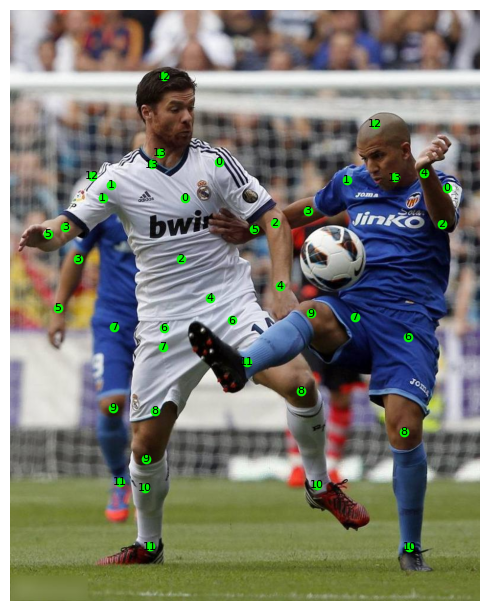


Visibility flags for all people:
tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


In [70]:
# Visualise predictions for a single image
img_tensor = torchvision.io.read_image(sample["img_path"])

ax = show_img_with_keypoints(
    img_tensor,
    keypoints=sample.get("keypoints"),
    visibility=sample.get("visibility"),
    include_occluded=True,
    numbered=True
)
keypoints = sample.get("keypoints")
#print(keypoints.shape)
mid_pt = keypoints.mean(dim=1)[0]  # Mid-hip point
plt.show()

visibility = sample.get("visibility")
print(f"\nVisibility flags for all people:")
print(visibility)


In [71]:
from src.data import CROWDPOSE_EDGE_LIST, make_edge_index, create_graph_from_keypoints

edge_index = make_edge_index(CROWDPOSE_EDGE_LIST)
g = create_graph_from_keypoints(edge_index, sample.get("keypoints").unsqueeze(0).repeat(2, 1, 1, 1))
print(f"edge_index: {g['edge_index'].shape}")   # (2, B*N*E)
print(f"node_pos:   {g['node_pos'].shape}")     # (B*N*K, 2)
print(f"batch:      {g['batch'].shape}")        # (B*N*K,)
print(f"batch_idx:  {g['batch_idx'].shape}")    # (B, N, K)
print(f"pose_idx:   {g['pose_idx'].shape}")     # (B, N, K)

# Example: select all nodes belonging to sample b=1
b = 1
mask = g['batch_idx'].reshape(-1) == b
print(f"\nNodes for sample b={b}: {g['node_pos'][mask].shape}")  # (N*K, 2)


edge_index: torch.Size([2, 168])
node_pos:   torch.Size([84, 2])
batch:      torch.Size([84])
batch_idx:  torch.Size([2, 3, 14])
pose_idx:   torch.Size([2, 3, 14])

Nodes for sample b=1: torch.Size([42, 2])


In [72]:
import torch_geometric as geom

graphsage = geom.nn.GraphSAGE(in_channels=2, hidden_channels=16, num_layers=2)
x = g['node_pos']  # (B*N*K, 2)
edge_index = g['edge_index']  # (2, B*N*E)
out = graphsage(x, edge_index)
print(f"GraphSAGE output: {out.shape}")  # (B*N*K,

GraphSAGE output: torch.Size([84, 16])


In [73]:
# Type of training augmentations:
# Pose dropout - Randomly drop some poses (i.e., mask out keypoints) with a certain probability. This simulates occlusions and encourages the model to learn from partial information.
# Joint dropout - Randomly drop some joints (i.e., mask out specific keypoints) with a certain probability. This simulates missing keypoints and encourages the model to learn from incomplete poses.
# Joint swapping - Randomly swap the positions of certain joints (e.g., left and right limbs) with a certain probability. This simulates pose variations and encourages the model to learn from different configurations.
# Limb swapping - Randomly swap the positions of entire limbs (e.g., swap the left arm with the right arm) with a certain probability. This simulates pose variations and encourages the model to learn from different configurations.
# Pose mixing - Randomly mix keypoints from different poses (e.g., combine upper body from one pose with lower body from another) with a certain probability. This simulates pose diversity and encourages the model to learn from a wider range of poses.
# Local image drop - Randomly drop the local conditioning 

# Training loss:
# Position loss - Compute the mean squared error (MSE) between the predicted keypoint positions and the ground truth keypoint positions. This encourages the model to learn accurate keypoint localization.
# Bone loss - Compute the MSE between the predicted bone lengths (i.e., distances between connected keypoints) and the ground truth bone lengths. This encourages the model to learn accurate pose structure.
# Visibility weighted loss - Weight the position and bone losses by the visibility flags of the keypoints. This encourages the model to focus more on visible keypoints and less on occluded keypoints. 

In [76]:
# Build DataLoader — batches are grouped by number of people so no padding is needed
train_loader = train_dataset.create_dataloader(batch_size=16, shuffle=True, drop_last=False)
val_loader = val_dataset.create_dataloader(batch_size=16, shuffle=False, drop_last=False)
test_loader = test_dataset.create_dataloader(batch_size=16, shuffle=False, drop_last=False)
print(f"Total batches: {len(train_loader)}")

batch = next(iter(train_loader))
for k, v in batch.items():
    print(k)
print(f"\nExample batch:")
print(f"  Images:          {len(batch['image_id'])}")
print(f"  Keypoints shape: {batch['keypoints'].shape}  — (B, N, K, 2)")


Total batches: 631
image_id
img_path
keypoints
visibility

Example batch:
  Images:          16
  Keypoints shape: torch.Size([16, 2, 14, 2])  — (B, N, K, 2)


In [81]:
from src.data import prepare_pose_graph_batch


pose_graph_batch = prepare_pose_graph_batch(batch["keypoints"], batch["visibility"])
pose_graph_batch.keys()

dict_keys(['edge_index', 'node_pos', 'batch', 'batch_idx', 'pose_idx', 'node_idx', 'visibility'])

In [86]:
from dataclasses import dataclass
from torch_geometric.nn import GAT


@dataclass
class KeypointDiffusionConfig:
    name: str
    dim_node: int = 128
    num_layers: int = 4
    dim_hidden: int = 128


class KeypointDiffusionModel(torch.nn.Module):
    def __init__(self, config: KeypointDiffusionConfig, num_keypoints: int = 14):
        super().__init__()
        self.config = config
        self.num_keypoints = num_keypoints

        self.position_embedding = torch.nn.Sequential(
            torch.nn.Linear(2, config.dim_node),
            torch.nn.LayerNorm(config.dim_node),
        )
        self.node_idx_embedding = torch.nn.Embedding(num_keypoints, config.dim_node)
        self.decoder = geom.nn.GAT(
            in_channels=2 * config.dim_node,
            hidden_channels=config.dim_hidden,
            num_layers=config.num_layers,
            out_channels=2,
        )

    def forward(self, node_pos, edge_index, node_idx, **kwargs):
        # node_pos: (B*N*K, 2)
        # edge_index: (2, B*N*E)
        # node_idx: (B*N*K,) — indices of keypoints (0 to K-1) for each node

        pos_emb = self.position_embedding(node_pos)  # (B*N*K, dim_node)
        idx_emb = self.node_idx_embedding(node_idx)  # (B*N*K, dim_node)
        x = torch.cat([pos_emb, idx_emb], dim=-1)  # (B*N*K, 2*dim_node)

        out = self.decoder(x, edge_index)  # (B*N*K, 2)
        return out
    

m = KeypointDiffusionModel(
    config=KeypointDiffusionConfig(name="test"),
    )
m(node_pos=pose_graph_batch["node_pos"], edge_index=pose_graph_batch["edge_index"], node_idx=pose_graph_batch["pose_idx"].reshape(-1)).shape

torch.Size([480, 2])